<a href="https://colab.research.google.com/github/Sanjana-s-space/Homework12-new/blob/main/Homework12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: ML Review

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework

In [1]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
!wget -qO- "https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/lfw.tar.gz" | tar xz

In [2]:
from random import randrange

from sklearn.metrics import classification_report, confusion_matrix

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from data_utils import LFWUtils
from data_utils import classification_error, display_confusion_matrix
from image_utils import make_image

## Face Unlock

Let's train a model to detect our face. We can think of this as a simpler version of one of the components inside something like the face ID software on our phones.

We'll skip the face detection part, which is when we find faces in an image, and assume we can get cropped and aligned faces out of images or video streams. We'll look at face detection later in the semester.

This is a slightly different kind of problem from the classification exercise we did in class, but the process is mostly the same.

We will use a dataset with other people's faces, but in the end we are only interested on how well our model detects our face.

### We Always Start with the Data

The dataset we're using is inside `./data/images/lfw/cropped`. It's a subset of the [Labeled Faces in the Wild](https://vis-www.cs.umass.edu/lfw/) dataset.

Take a look at the directory.

What's there?

How's the data organized and labeled?

### Loading the Data

Since we're not interested in generic classification, and measuring how we do on unlabeled data, this whole dataset is labeled, and we can read it into `train` and `test` subsets by calling the `train_test_split()` function of the `LFWUtils` class.

This function takes an optional parameter that specifies what portion of the data should be used for the `test` dataset. We can start with the default value of $0.5$.

In [3]:
train, test = LFWUtils.train_test_split(dir="./data/image/lfw/cropped", test_pct=0.5)

### Looking at the Data

Ok. Data is loaded.

What's in the data? How is it actually organized?

Take a look at the objects that were returned in each of the $2$ variables.

How big are our datasets?

Take a look at the `LABELS` and `L2I` members of the `LFWUtils` class (`LFWUtils.LABELS` and `LFWUtils.L2I`).

In [5]:
# TODO: look at dataset objects (train and test variables). What's in them?
print("Training dataset type:", type(train))
print("Training dataset keys:", train.keys())

print("Testing dataset type:", type(test))
print("Testing dataset keys:", test.keys())

# TODO: how big are them? (how many records?)
print("\nTraining dataset:")
for key in train:
    print(key, ":", len(train[key]))

print("\nTesting dataset:")
for key in test:
    print(key, ":", len(test[key]))

# TODO: how many labels do they have?
print("\nNumber of labels:", len(LFWUtils.LABELS))


# TODO: what are the labels
print("\nLabels:")
print(LFWUtils.LABELS)

# label-to-index mapping
print("\nLabel-to-index mapping:")
print(LFWUtils.L2I)

Training dataset type: <class 'dict'>
Training dataset keys: dict_keys(['pixels', 'labels', 'files'])
Testing dataset type: <class 'dict'>
Testing dataset keys: dict_keys(['pixels', 'labels', 'files'])

Training dataset:
pixels : 445
labels : 445
files : 445

Testing dataset:
pixels : 438
labels : 438
files : 438

Number of labels: 25

Labels:
['annan', 'arroyo', 'berlusconi', 'blair', 'bushgw', 'bushl', 'chavez', 'clintonb', 'erdogan', 'fox', 'giuliani', 'jolie', 'koizumi', 'lopez', 'lula', 'mauresmo', 'moohyun', 'powell', 'putin', 'ryder', 'schwarzenegger', 'sukarnoputri', 'watts', 'williams', 'woods']

Label-to-index mapping:
{'annan': 0, 'arroyo': 1, 'berlusconi': 2, 'blair': 3, 'bushgw': 4, 'bushl': 5, 'chavez': 6, 'clintonb': 7, 'erdogan': 8, 'fox': 9, 'giuliani': 10, 'jolie': 11, 'koizumi': 12, 'lopez': 13, 'lula': 14, 'mauresmo': 15, 'moohyun': 16, 'powell': 17, 'putin': 18, 'ryder': 19, 'schwarzenegger': 20, 'sukarnoputri': 21, 'watts': 22, 'williams': 23, 'woods': 24}


### Visualizing the Data

We can open some random images to make sure the content of our datasets make sense.

Our `LFWUtils` class has some member variables that hold the image dimensions (`LFWUtils.IMAGE_SIZE`, `LFWUtils.IMAGE_WIDTH`, `LFWUtils.IMAGE_HEIGHT`)

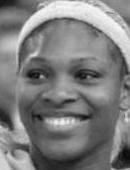

id: 23 
label: williams 
from: williams-012.jpg


In [6]:
train_size = len(train["labels"])
ridx = randrange(0, train_size)

label_id = train["labels"][ridx]

display(make_image(train["pixels"][ridx], width=LFWUtils.IMAGE_SIZE[0]))

print("id:", label_id,
      "\nlabel:", LFWUtils.LABELS[label_id],
      "\nfrom:", train["files"][ridx])

### Adding your images

Create a directory in the `dataset` directory for your images. Give it a one-word name, like your last name, your New School id or your initials. For example, mine is called `tgh` and is located at: `./data/images/lfw/cropped/tgh`.

Now, add between $20$ and $30$ images of your face to your directory.

The images should be just like the ones that are already there for the other people:
- $130$ pixels wide
- $170$ pixels tall
- single-channel grayscale
- jpeg format
- named `label-number.jpg` (for example: `tgh-000.jpg`)

Feel free to do this manually using Photoshop or any other image editing software, but the easiest way is to use this interface that automatically crops faces out of pictures and creates images in the correct format:

### [Face Align](https://huggingface.co/spaces/visualizedata/PSAM5020-FaceAlign-Gradio)

It will also align the faces and put the eyes in a consistent location. There's even an option to capture pictures from a live camera stream.

### Reload Dataset

Just run the `train_test_split()` again.

### PCA, Classification, etc etc etc

Now that we have added our images to the dataset, let's train a classifier and see how well it performs on not just classification, but on recognizing our face.

The images are $130$ x $170$ ($22\text{,}100$ pixels), so let's do `PCA`. We can aim for an explained variance value of about $80\%$, and adjust that later if we find necessary.

Once we have the PCs for our training dataset in a `DataFrame` we can add a `label` column to it with the correct labels we have in `train["labels"]`.

We can also create a `DataFrame` for testing now by using the same `PCA` object to `transform()` the `test["pixels"]` data.

Since we won't train anything with the test dataset, it's ok to just keep the labels in `test["labels"]` as they are.

In [7]:
import pandas as pd

# create PCA, fit and transform train data
pca = PCA(n_components=0.8)
train_pcs = pca.fit_transform(train["pixels"])

# check PCA captured variance
print("Explained variance:", pca.explained_variance_ratio_.sum())
print("Number of principal components:", pca.n_components_)

# prepare DataFrame for training (add label column)
train_df = pd.DataFrame(train_pcs)
train_df["label"] = train["labels"]

display(train_df.head())

# create the test DataFrame by running PCA on the test data
test_pcs = pca.transform(test["pixels"])
test_df = pd.DataFrame(test_pcs)

display(test_df.head())

Explained variance: 0.80158417722807
Number of principal components: 31


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,label
0,1640.648364,1908.893130,-365.276956,-2852.705429,749.240951,5030.396652,967.432805,-3807.047714,198.347515,-1946.122414,...,-948.856724,1576.795353,-855.102964,-715.810710,-67.554560,69.329770,-812.271632,705.138790,-182.276472,0
1,8036.046890,-3645.361354,-2419.079211,4031.049028,-1536.783208,-1689.294667,3638.509724,-2391.220613,1383.970137,542.262118,...,-915.011041,-364.562903,-154.702876,871.706625,-170.804902,291.113354,71.542783,869.875434,-506.824807,0
2,3469.078905,852.399294,-6230.765782,593.239895,169.642773,1027.930398,4439.072570,57.778728,-126.569963,1366.029989,...,-203.720499,1184.986129,-525.450260,397.497896,-163.115502,-179.720137,235.947723,155.358877,265.967550,0
3,-1621.654329,-3453.771453,-4152.310709,-883.437785,-613.023108,189.600981,592.132253,-328.133756,2384.996735,625.627112,...,258.674124,340.826592,63.178185,-93.531218,250.029669,-248.880097,-615.084865,-134.088546,136.047596,0
4,2901.799566,2303.029334,-5449.771928,793.180002,1870.927003,2102.447985,238.209038,799.204656,2871.501224,-1267.912997,...,286.836466,-167.489325,3.205623,-823.740858,172.936983,47.216158,-815.013614,599.257492,-386.829661,0


,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,-2988.208963,-1014.628325,-4544.706165,795.280925,-1228.906249,53.686341,3592.508036,-2145.226160,-52.431500,531.887957,...,-456.509399,-6.708905,102.075225,646.661933,-11.104158,-109.770859,285.566970,244.097717,-87.571065,-57.501540
1,-1359.088860,-1359.177403,-5954.688067,-1048.005949,335.778928,-98.530476,571.851223,1221.056271,639.290097,451.609007,...,156.174488,-472.712923,638.822411,-325.839232,241.793888,-494.765609,-593.061192,859.259405,-734.196703,-0.302169
2,-2225.035577,-469.385593,-4355.015036,-2103.652953,-287.423086,372.804161,557.789849,1009.435320,1460.136316,-178.720512,...,330.629099,602.818130,-274.198871,673.854986,-363.881185,-148.290204,-1254.529850,-490.724876,226.418875,-173.840932
3,692.703790,624.045194,-1864.669488,235.955274,-984.126286,887.588075,3007.881827,-774.580594,-1141.719827,590.077426,...,995.972320,-67.641573,393.672371,-36.432677,-238.158350,-740.750483,-317.315374,-289.030137,536.967730,1176.252298
4,-798.153091,-1267.902822,-2686.019858,124.409698,-1512.005984,1406.935543,2287.121543,-824.049783,-1396.439348,1856.049764,...,1030.270824,198.090212,-24.518437,-402.663600,-357.081026,-1328.158273,-120.909837,-328.416360,57.347086,1019.186766


We can use the following cell to take a look at our images and their reconstructions.

This assumes the `DataFrame` is called `train_df` and the `PCA` object is called `face_pca`. Adjust these if necessary.

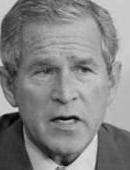

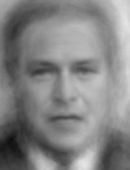

In [9]:
train_size = len(train["labels"])
ridx = randrange(0, train_size)

# reconstruct image
pca_pixels = pca.inverse_transform(train_df.iloc[[ridx]].drop(columns=["label"]))

display(make_image(train["pixels"][ridx], width=LFWUtils.IMAGE_SIZE[0]))
display(make_image(pca_pixels, width=LFWUtils.IMAGE_SIZE[0]))

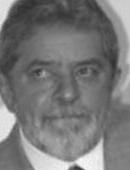

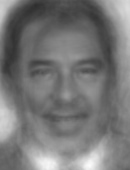

In [10]:
# filter the DataFrame by our label
awesome_df = train_df[train_df["label"] == LFWUtils.L2I["lula"]]

# index of image with our label
img_idx = 0
awesome_idx = awesome_df.index[img_idx]

# reconstruct image
pca_pixels = pca.inverse_transform(awesome_df.iloc[[img_idx]].drop(columns=["label"]))

display(make_image(train["pixels"][awesome_idx], width=LFWUtils.IMAGE_WIDTH))
display(make_image(pca_pixels, width=LFWUtils.IMAGE_WIDTH))

### Interpretation

<span style="color:hotpink;">
Do these make sense ? Do they look "recognizable" ? How do they change as a function of `PCA` <code>n_components</code> ?
</span>

<span style="color:hotpink;">Yes, the reconstructed images make sense and are still somewhat recognizable. Even though they are blurry compared to the original images, we can still see the basic facial features, such as the eyes, nose, mouth, and overall face shape. However, some finer details, textures, and facial expressions are lost during the reconstruction.

As we increase the `n_components` value in PCA, the reconstructed images should become clearer and closer to the original images because more information is retained. When we decrease the number of components, the images should become blurrier and lose more facial details.

I think PCA is useful because it reduces the amount of data while still preserving important facial features that could help the model with classification. However, choosing too few components might make it difficult for the model to distinguish between different faces.</span>

Now, back to classifying...

Maybe start with `RandomForestClassifier()` or `SVC()`...

In [12]:
# TODO: create a classifier
model = RandomForestClassifier()

# TODO: separate input and output columns from the train DataFrame
train_features = train_df.drop(columns=["label"])
train_labels = train_df["label"]

# TODO: train model using train data and labels
model.fit(train_features, train_labels)

# TODO: run prediction on train data
train_predictions = model.predict(train_features)


### Validate model with training data

error: 0.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00        22
           2       1.00      1.00      1.00        17
           3       1.00      1.00      1.00        24
           4       1.00      1.00      1.00        24
           5       1.00      1.00      1.00        19
           6       1.00      1.00      1.00        24
           7       1.00      1.00      1.00        14
           8       1.00      1.00      1.00        15
           9       1.00      1.00      1.00        16
          10       1.00      1.00      1.00        13
          11       1.00      1.00      1.00        10
          12       1.00      1.00      1.00        24
          13       1.00      1.00      1.00        11
          14       1.00      1.00      1.00        24
          15       1.00      1.00      1.00        11
          16       1.00      1.00      1.00        16
          17    

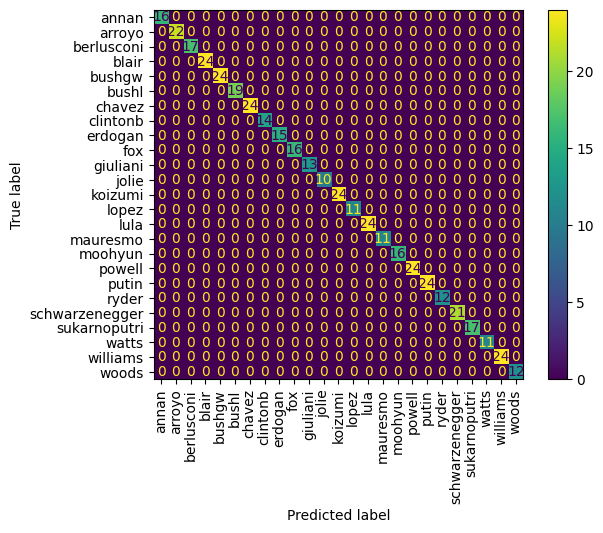

In [13]:
# measure classification error
print("error:", classification_error(train["labels"], train_predictions))

# look at precision/recall from classification_report
print(classification_report(train["labels"], train_predictions))

# look at confusion matrix
display_confusion_matrix(train["labels"], train_predictions, LFWUtils.LABELS)

### Interpretation

<span style="color:hotpink;">
How does the confusion matrix look ? What does it mean ?
</span>

<span style="color:hotpink;">The confusion matrix looks good as all the values are along the diagonal, and the rest are zero. This means that the model was able to correctly classify all the images in the training dataset with 100% accuracy.

However, I think there might be a possibility of overfitting since we are testing the model on the same data it was trained on. It would be interesting to see how well the model performs on the test dataset and whether it can correctly classify images it has not seen before.</span>

Validate model with testing data

Testing classification error: 0.634703196347032
              precision    recall  f1-score   support

           0       0.50      0.20      0.29        15
           1       0.55      0.55      0.55        22
           2       0.17      0.06      0.09        16
           3       0.10      0.12      0.11        24
           4       0.21      0.33      0.26        24
           5       0.62      0.79      0.70        19
           6       0.16      0.12      0.14        24
           7       0.33      0.21      0.26        14
           8       0.50      0.07      0.12        14
           9       0.20      0.12      0.15        16
          10       0.00      0.00      0.00        13
          11       0.00      0.00      0.00        10
          12       0.43      0.83      0.57        24
          13       0.00      0.00      0.00        10
          14       0.39      0.62      0.48        24
          15       0.00      0.00      0.00        10
          16       0.75      0.56

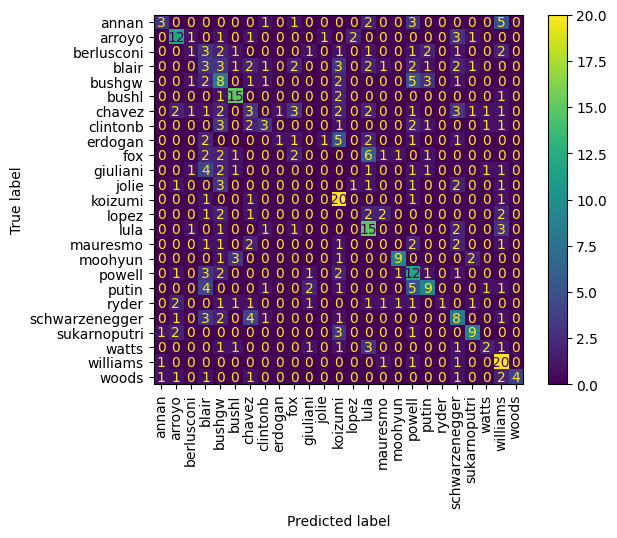

In [15]:
# TODO: run prediction on test data
test_predictions = model.predict(test_df)

# TODO: measure classification error
test_error = classification_error(test["labels"], test_predictions)
print("Testing classification error:", test_error)

# TODO: look at precision/recall from classification_report
print(classification_report(
    test["labels"],
    test_predictions,
    zero_division=0
))
# TODO: look at confusion matrix
display_confusion_matrix(
    test["labels"],
    test_predictions,
    LFWUtils.LABELS
)

### Different Classifiers

Try changing the classifier type above, or some of its parameters, to see if the overall accuracy can be improved.

Some things to try:
- `SVC(kernel="linear")`: this changes the type of curve the model tries to use to separate our classes. The more complex default type (`rbf`) might be over-fitting the data. We can experiment with `linear` or `poly` curves.
- `LogisticRegression()`: the classification that fits statistical modeling functions (bell curves) to our data.


### Hyper-parameter Optimization

Each model type has a handful of parameters that can be adjusted and optimized.

For example, we could add "regularization" to a `LogisticRegression` classifier with `C=0.1`.

Regularization is a process that makes training harder by setting more restrictions on the kind of answers it can give.

This can be restrictions like:
- keep all calculated parameters close to $0$
- minimize the number of non-zero parameters used
- keep all parameters positive

The result is slightly worse performance on the training dataset, but hopefully better generalization of the model and better performance on the test dataset.

SVC classification error: 0.5753424657534247
SVC accuracy: 42.46575342465753
Previous PCA components: 31
New PCA components: 76
Accuracy with 80% PCA: 42.46575342465753
Accuracy with 90% PCA: 46.80365296803652


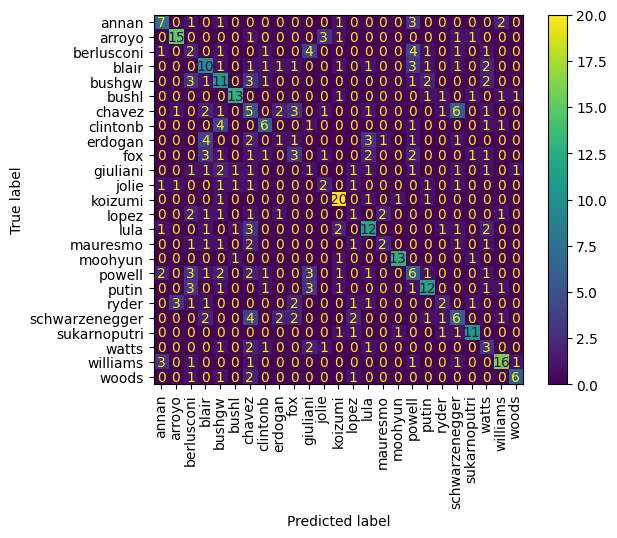

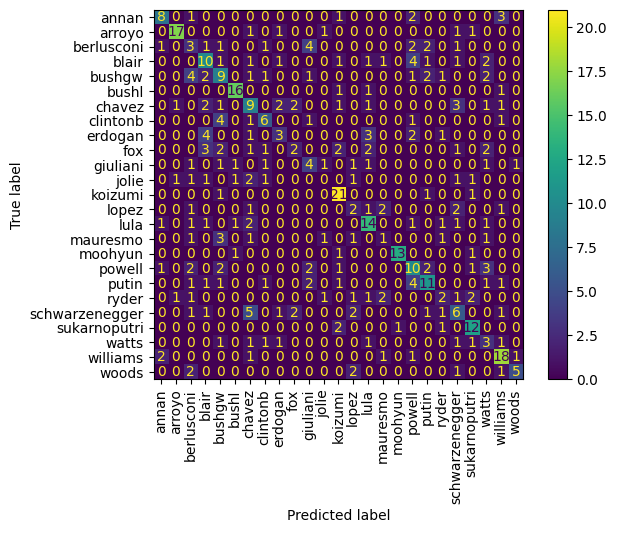

In [18]:
# TODO: try LogisticRegression() and/or SVC(kernel="linear")

# Train SVC classifier
svc_model = SVC(kernel="linear")
svc_model.fit(train_features, train_labels)

# Run predictions
svc_predictions = svc_model.predict(test_df)

# Measure classification error and accuracy
svc_error = classification_error(test["labels"], svc_predictions)

print("SVC classification error:", svc_error)
print("SVC accuracy:", (1 - svc_error) * 100)

# Display confusion matrix
display_confusion_matrix(
    test["labels"],
    svc_predictions,
    LFWUtils.LABELS
)


# TODO: does adding features (increasing PCA components) help ?

# Increase PCA explained variance to 90%
pca_new = PCA(n_components=0.9)

# Transform training and testing data
train_pcs_new = pca_new.fit_transform(train["pixels"])
test_pcs_new = pca_new.transform(test["pixels"])

# Create DataFrames
train_df_new = pd.DataFrame(train_pcs_new)
test_df_new = pd.DataFrame(test_pcs_new)

# Train SVC with increased PCA components
model_new = SVC(kernel="linear")
model_new.fit(train_df_new, train["labels"])

# Run predictions
predictions_new = model_new.predict(test_df_new)

# Measure classification error and accuracy
error_new = classification_error(test["labels"], predictions_new)

print("Previous PCA components:", pca.n_components_)
print("New PCA components:", pca_new.n_components_)

print("Accuracy with 80% PCA:", (1 - svc_error) * 100)
print("Accuracy with 90% PCA:", (1 - error_new) * 100)

# Display confusion matrix
display_confusion_matrix(
    test["labels"],
    predictions_new,
    LFWUtils.LABELS
)

### Interpretation

<span style="color:hotpink;">
How does THIS confusion matrix look ? What does it mean ? How does it perform for your pictures ?
</span>

<span style="color:hotpink;">The confusion matrices look slightly better compared to the previous Random Forest model. The accuracy increased from 36.53% to 42.47% when I switched to the SVC classifier with a linear kernel.

When I increased the PCA explained variance from 80% to 90%, the number of components increased from 31 to 76, and the accuracy further improved to 46.80%. I noticed that more values appeared along the diagonal, which means that the model was able to correctly classify more images. However, there are still several incorrect predictions outside the diagonal.

From this experiment, I think increasing the PCA components helped the model retain more facial details and improved its performance. However, the overall accuracy is still below 50%, so there is room for improvement.

I cannot determine how well the model performs on my own pictures yet, as my personal image label is not present in the confusion matrices.</span>

### Precision and Recall

Accuracy, which is the complement of our `classification_error` value, is the measurement that is optimized during the `RandomForestClassifier` training process.

If we were training a regular classifier, we would look at `accuracy` (or `classification_error`) to determine if our model's performance is acceptable.

Since we're working on a personal face recognition model, we don't really care about overall accuracy, but instead are more interested in the `precision` and `recall` values for the classification of our particular images.

We don't want overall accuracy to be horrible, but we can be more specific in this case and be happy if the correct portion of our confusion matrix looks good.

Calculate the `precision` and `recall` values for the classification of your images.

In [19]:
# Select an existing label
my_label = LFWUtils.L2I["koizumi"]

# Calculate confusion matrix
cm = confusion_matrix(test["labels"], predictions_new)

# TODO: calculate precision
true_positive = cm[my_label, my_label]

precision = true_positive / cm[:, my_label].sum()

print("Precision:", precision)


# TODO: calculate recall
recall = true_positive / cm[my_label, :].sum()

print("Recall:", recall)

Precision: 0.65625
Recall: 0.875


### Interpretation

<span style="color:hotpink;">
How is it performing for your images ? Which value, precision or recall, is higher ? What does that mean ?
</span>

<span style="color:hotpink;">Since I have not added my own images to the dataset, I used an existing label to evaluate the model's performance. For the selected label, recall is higher than precision. This means that the model is able to correctly recognize most of the actual images belonging to that label, but it also incorrectly classifies some other images as belonging to the same label.

For a face unlock system, I think higher precision would be more important because we want to prevent unauthorized users from gaining access. However, having a good balance between precision and recall would make the system more reliable.

I would need to add my own images to evaluate how well the model recognizes me.</span>

We can run the following cell to see which classes have the highest `precision` and `recall` scores:

In [20]:
print("top precision:", LFWUtils.top_precision(test["labels"], test_predictions, top=5))
print("top recall:", LFWUtils.top_recall(test["labels"], test_predictions, top=5))

top precision: ['woods', 'ryder', 'moohyun', 'bushl', 'sukarnoputri']
top recall: ['williams', 'koizumi', 'bushl', 'lula', 'moohyun']
